# ECE1512 Project A - Build an ABMIL training pipeline in PyTorch

This notebook uses pre-extracted whole-slide histopathology features and guides you through a complete PyTorch classification pipeline. The goal is not merely to run ABMIL; it is to understand the code path from data loading to optimization, validation, checkpoint selection, and final testing.

Please complete every cell marked `TODO`. Dataset engineering and metric boilerplate are provided so you can focus on the machine-learning training workflow.

This project requires basic familiarity with Python object-oriented programming (OOP). If you have limited experience with Python OOP, please review the provided introductory video before starting the project. 

[PyTorch](https://docs.pytorch.org/tutorials/beginner/introyt/introyt1_tutorial.html)

[Python Object-Oriented Programming ](https://www.youtube.com/watch?v=JeznW_7DlB0)

**Research extension:** Propose two research ideas and implement and evaluate one selected idea. Report ABMIL baseline and selected-extension results on **CAMELYON16, CAMELYON17, and BRACS**, using the same features and train/validation/test splits within each dataset. 


## Learning objectives

After this project you should be able to explain and implement:

1. `Dataset` vs. `DataLoader`, batching, shuffling.
2. `nn.Module`, trainable parameters, and `forward()`.
3. A classification loss and optimizer.
4. The training sequence `zero_grad -> forward -> loss -> backward -> step`.
5. The difference between `model.train()` and `model.eval()`.

## Step 0. Download Pre-extracted WSI Features & Select the Project Directory
Download the required feature file(s) from Zenodo or Hugging Face:

https://zenodo.org/records/23130543

https://huggingface.co/datasets/LeonYe/ECE1512-WSI-Feature


Place the HDF5 file under the path expected by your YAML configuration in the `config/`, or edit data_dir in the YAML file.


In [25]:
!pip install -q torchmetrics h5py pandas scikit-learn pyyaml matplotlib openslide-python openslide-bin


In [1]:
import os, sys, copy, time
from pathlib import Path
import matplotlib.pyplot as plt
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader

import json

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

from utils import TODO


PyTorch: 2.15.0+cpu
CUDA available: False


If you are using Google Colab with Drive, mount Drive first and change `PROJECT_DIR`.

In [49]:
# # Optional in Google Colab:
# from google.colab import drive
# drive.mount('/content/drive')

PROJECT_DIR = './'
DATASET = 'BRACS'  # Choose: 'C16', 'C17', or 'BRACS'

CONFIG_FILES = {
    'C16': 'camelyon16_medical_ssl_config.yml',
    'C17': 'camelyon17_medical_ssl_config.yml',
    'BRACS': 'bracs_medical_ssl_config.yml',
}

CONFIG_PATH = os.path.join(PROJECT_DIR, 'config', CONFIG_FILES[DATASET])

if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)

print('Project:', os.path.abspath(PROJECT_DIR))
print('Config :', CONFIG_PATH)

from wsi_visualization import visualize_wsi_attention


Project: c:\Project_A_Starter_Code
Config : ./config\bracs_medical_ssl_config.yml


In [50]:
from dataloader import build_HDF5_feat_dataset, mil_collate_fn
from utils import load_config, seed_everything, infer_feature_dim, classification_metrics

conf = load_config(CONFIG_PATH)
seed_everything(int(conf.seed))
print(conf)

if os.path.exists(conf.data_dir):
    print('Feature file exists:', os.path.exists(conf.data_dir), conf.data_dir)
else:
    print('\nDownload the required feature file from: https://zenodo.org/records/23130543')
    print('Then update data_dir in:', CONFIG_PATH)
    

Struct(B=1, D_attn=128, D_feat=384, D_inner=256, data_dir='./feature/BRACS/patch_feats_pretrain_medical_ssl.h5', dataset='BRACS', dataset_csv_dir='./dataset_csv', droprate=0.0, lr=0.0001, n_class=7, n_res=0, n_shot=0, n_worker=0, pin_memory=True, seed=42, train_epoch=30, warmup_epoch=3, wd=1e-05)
Feature file exists: True ./feature/BRACS/patch_feats_pretrain_medical_ssl.h5


# Step 1 - Dataset and DataLoader

`build_HDF5_feat_dataset` is provided. It creates train/validation/test `Dataset` objects without loading all slide features into memory at once.


Complete the three `DataLoader` definitions. Think about which split should be shuffled.

[Download WSI datasets](https://zenodo.org/records/23130543)

[Datasets & DataLoaders](https://docs.pytorch.org/tutorials/beginner/basics/data_tutorial.html)


[PyTorch DataLoader](https://docs.pytorch.org/docs/2.14/data.html#torch.utils.data.DataLoader)


[PyTorch Datasets](https://docs.pytorch.org/vision/stable/datasets.html)


In [51]:
# data is alreday split into patch feature embeddings
train_data, val_data, test_data = build_HDF5_feat_dataset(conf.data_dir, conf)

# determines feature vectors dimensionality 
conf.D_feat = infer_feature_dim(train_data)
print('Split sizes: Train {}, Validation {}, Test {};'.format(len(train_data), len(val_data), len(test_data)))
print("Feature Shape: {};".format(tuple(train_data[1]['input'].shape)))

# the ground-truth classification (postive or negative)
print("Label: {}; \nSlide ID: {}.".format(train_data[1]['label'], train_data[1]['slide_id']))

Split sizes: Train 389, Validation 62, Test 86;
Feature Shape: (7540, 384);
Label: 1; 
Slide ID: BRACS_1003659.


In [52]:
batch_size=conf.B
num_workers=int(conf.n_worker)
pin_memory=bool(conf.pin_memory) and torch.cuda.is_available()
collate_fn=mil_collate_fn
print("DataLoader args: Batch size {}; \n \
      # CPUs {};  \n \
      pin_memory {};  \n \
      collate_fn {}".format(batch_size, num_workers, pin_memory, collate_fn))


DataLoader args: Batch size 1; 
       # CPUs 0;  
       pin_memory False;  
       collate_fn <function mil_collate_fn at 0x000002540FCA5F80>


In [53]:
# TODO 1A: create the training DataLoader. Training data should be shuffled.
# train_loader = TODO('Create DataLoader(train_data, shuffle=..., ...)')

train_loader = DataLoader(
    train_data,
    batch_size=batch_size,
    shuffle=True,
    num_workers=num_workers,
    pin_memory=pin_memory,
    collate_fn=collate_fn
)

# TODO 1B: create validation and test DataLoaders. Do not shuffle them.
# val_loader = TODO('Create validation DataLoader')

val_loader = DataLoader(
    val_data,
    batch_size=batch_size,
    shuffle=False,
    num_workers=num_workers,
    pin_memory=pin_memory,
    collate_fn=collate_fn
)


# test_loader = TODO('Create test DataLoader')
test_loader = DataLoader(
    test_data,
    batch_size=batch_size,
    shuffle=False,
    num_workers=num_workers,
    pin_memory=pin_memory,
    collate_fn=collate_fn
)


In [54]:
# Inspect one MIL batch.
batch = next(iter(train_loader))
print('input:', tuple(batch['input'].shape), batch['input'].dtype)
print('label:', tuple(batch['label'].shape), batch['label'].dtype)
print('slide IDs:', batch['slide_id'])

input: (1, 16307, 384) torch.float32
label: (1,) torch.int64
slide IDs: ['BRACS_1915']


**Questions for your report:**

- What is the difference between a `Dataset` and a `DataLoader`?
- Which Dataloader should use `shuffle=True`? Why?
- For a batch with input shape `[B, N, D]`, what do `B`, `N`, and `D` mean in this project?


# Step 2 - Implement the ABMIL model

For each patch feature $h_i$, the gated attention score follows Ilse et al. (2018):

$$
a_i = w^T\left[\tanh(Vh_i) \odot \sigma(Uh_i)\right].
$$

The attention logits are normalized over instances:

$$
\alpha_i = \frac{\exp(a_i)}{\sum_j \exp(a_j)},
$$

and the slide representation is

$$
z = \sum_i \alpha_i h_i.
$$

You will implement the learnable layers and the key `forward()` operations.

[Custom nn Modules](https://docs.pytorch.org/tutorials/beginner/examples_nn/polynomial_module.html)

[nn.Linear](https://docs.pytorch.org/docs/2.14/generated/torch.nn.Linear.html)

[nn.modules.dropout](https://docs.pytorch.org/docs/2.14/generated/torch.nn.Dropout.html)

[nn.ReLU](https://docs.pytorch.org/docs/2.14/generated/torch.nn.ReLU.html)

[torch.nn.functional.softmax (F.softmax)](https://docs.pytorch.org/docs/2.14/generated/torch.nn.functional.softmax.html)

[torch.bmm](https://docs.pytorch.org/docs/2.14/generated/torch.bmm.html)

In [55]:
class Classifier1FC(nn.Module):
    def __init__(self, n_channels, n_classes, droprate=0.0):
        super().__init__()

        #sets some feature values to zero to avoid over fitting
        self.dropout = nn.Dropout(droprate) if droprate > 0 else nn.Identity()
        # TODO 2A: one linear layer from n_channels to n_classes.

        #outputs 2 classification scores called logits
        self.fc = nn.Linear(n_channels, n_classes)

    def forward(self, x):
        # TODO 2B: apply dropout, then the classifier.
        return self.fc(self.dropout(x))


# reduces the feature vector to a smaller size (ex: 382 -> 256)
class DimReduction(nn.Module):
    def __init__(self, n_channels, m_dim):
        super().__init__()
        # TODO 2C: project patch features to m_dim and use ReLU.

        # process of adjusting feature vetor size
        self.fc = nn.Linear(n_channels, m_dim)
        self.relu = nn.ReLU()

    def forward(self, x):
        # TODO 2D: linear projection followed by ReLU.
        return self.relu(self.fc(x))

#L=input feature dimension, D=Hidden deimension used for attention, K=no. of attention scores per patch
class AttentionGated(nn.Module):
    def __init__(self, L=256, D=128, K=1):
        super().__init__()
        self.attention_V = nn.Sequential(nn.Linear(L, D), nn.Tanh())
        self.attention_U = nn.Sequential(nn.Linear(L, D), nn.Sigmoid())

        self.attention_weights_w = nn.Linear(D, K)

    def forward(self, x):
        # x: [B, N, L]
        # TODO 2E: implement the two gated branches.
        a_v = self.attention_V(x)
        a_u = self.attention_U(x)

        # returns one attention score per patch
        a = self.attention_weights_w(a_v * a_u)
        return a.transpose(1, 2)             


class ABMIL(nn.Module):
    def __init__(self, conf):
        super().__init__()
        self.dimreduction = DimReduction(conf.D_feat, conf.D_inner)
        self.attention = AttentionGated(conf.D_inner, conf.D_attn, K=1)
        self.classifier = Classifier1FC(conf.D_inner, conf.n_class, conf.droprate)

    def forward(self, x, return_attention=False):
        # x: [B, N, D_feat]
        med_feat = self.dimreduction(x)       # [B, N, D_inner]  --> featured reduction
        a_logits = self.attention(med_feat)   # [B, 1, N]   --> compute raw attention scores


        # TODO 2G: normalize attention logits over the instance dimension.
        attention = F.softmax(a_logits, dim=2)
        #TODO('Apply softmax over patches')
        
        # TODO 2H: weighted aggregation. torch.bmm is useful here.

        #combines all patch representations into one feature vector representing the whole slide
        bag_feat = torch.bmm(attention, med_feat).squeeze(1)
        #TODO('Aggregate patch features into one slide representation')

        # TODO 2I: classify the slide representation.

        #converts final feature vector into one score per class (pos or neg)
        logits = self.classifier(bag_feat)
        #TODO('Compute slide-level logits')

        if return_attention:
            return logits, attention
        return logits


**Sanity Check**

Before running the full training pipeline, check the tensor shapes and attention normalization.


In [56]:
model_cpu = ABMIL(conf).eval()

x_demo = torch.randn(2, 7, conf.D_feat)


with torch.no_grad():
    logits_demo, attn_demo = model_cpu(x_demo, return_attention=True)

print('logits:', logits_demo.shape)
print('attention:', attn_demo.shape)
print('attention sums:', attn_demo.sum(dim=-1))

assert logits_demo.shape == (2, int(conf.n_class))
assert attn_demo.shape == (2, 1, 7)
torch.testing.assert_close(attn_demo.sum(dim=-1), torch.ones(2, 1))
print('Sanity check passed.')


logits: torch.Size([2, 7])
attention: torch.Size([2, 1, 7])
attention sums: tensor([[1.0000],
        [1.0000]])
Sanity check passed.


**Questions:**

- Which tensors in your model contain trainable parameters?
- What properties do attention weights have after softmax?
- Could we replace softmax with another function?


# Step 3 - Device, loss, and optimizer

For multi-class slide classification, use cross-entropy as the baseline objective and AdamW as the baseline optimizer. Complete the code below.

[nn.CrossEntropyLoss](https://docs.pytorch.org/docs/2.14/generated/torch.nn.CrossEntropyLoss.html)

[torch.optim.AdamW](https://docs.pytorch.org/docs/2.14/generated/torch.optim.AdamW.html)

In [57]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = ABMIL(conf).to(device)


# measures how incorrect the model's predictions are compared with the true slide labels

# TODO 3A: define the multi-class classification loss.
criterion = nn.CrossEntropyLoss()

# AdamW is the optimization algorithm used to update the model's trainable weights

# TODO 3B: create AdamW and pass the model parameters, learning rate, and weight decay.
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=conf.lr,
    weight_decay=conf.wd
)
#TODO('Create torch.optim.AdamW(...)')

print('Device:', device)
print('Trainable parameters:', sum(p.numel() for p in model.parameters() if p.requires_grad))


Device: cpu
Trainable parameters: 166280


# Step 4 - Complete one training epoch

The essential PyTorch optimization sequence is:

`model.train()` -> move tensors to device -> `zero_grad()` -> forward pass -> compute loss -> `backward()` -> `step()`.

Implement this sequence yourself. This is one of the main learning objectives of the project.

[Training with PyTorch](https://docs.pytorch.org/tutorials/beginner/introyt/trainingyt.html)

[train() vs eval()](https://discuss.pytorch.org/t/model-train-and-model-eval-vs-model-and-model-eval/5744)

In [58]:
def train_one_epoch(model, criterion, data_loader, optimizer, device):
    # TODO 4A: put the model in training mode.
    model.train()
    #TODO('Call model.train()')

    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    for data in data_loader:
        # TODO 4B: move input and labels to the selected device.
        bag = data['input'].to(device, dtype=torch.float32)
        #TODO('Move data["input"] to device as float32')
        labels = data['label'].to(device, dtype=torch.long)
        #TODO('Move data["label"] to device as long')

        # TODO 4C: clear gradients from the previous iteration.
        optimizer.zero_grad()
        #TODO('optimizer zero grad')

        # TODO 4D: forward pass.

        # run a slide through the BMIL model
        logits = model(bag)
        #TODO('Pass the feature bag to the ABMIL')

        # TODO 4E: compute the loss.
        loss = criterion(logits, labels)
        #TODO('criterion(logits, labels)')

        # TODO 4F: back-propagate gradients.
        loss.backward()
        #TODO('loss.backward()')

        # TODO 4G: update the model parameters.
        optimizer.step()
        #TODO('optimizer.step()')

        # how many WSIs are in the current batch
        batch_size = labels.shape[0]

        #sum total loss
        total_loss += loss.item() * batch_size

        #sum correct predictions 
        total_correct += (logits.argmax(dim=1) == labels).sum().item()

        #count processed WSIs
        total_examples += batch_size

    return {
        'loss': total_loss / total_examples,
        'acc': 100.0 * total_correct / total_examples,
    }


# Step 5 - Validation and test evaluation

Evaluation should not update the model. Complete the missing lines and use the provided metric helper for macro-AUROC and macro-F1.


In [59]:
@torch.no_grad()
def evaluate(model, criterion, data_loader, device, conf):
    # TODO 5A: switch to evaluation mode.
    model.eval()
    #TODO('Call model.eval()')

    total_loss = 0.0
    total_examples = 0
    probabilities_all = []
    labels_all = []

    for data in data_loader:
        # TODO 5B: move data to device.
        bag = data['input'].to(device)
        #TODO('Move input to device')
        labels = data['label'].to(device)
        #TODO('Move labels to device')

        # TODO 5C: forward pass and loss.
        logits = model(bag)
        loss = criterion(logits, labels)

        # TODO 5D: convert class logits into probabilities.
        probabilities = torch.softmax(logits, dim=1)
        #TODO('Apply softmax over classes')

        total_loss += loss.item() * labels.shape[0]
        total_examples += labels.shape[0]
        probabilities_all.append(probabilities)
        labels_all.append(labels)

    probabilities_all = torch.cat(probabilities_all, dim=0)
    labels_all = torch.cat(labels_all, dim=0)
    metrics = classification_metrics(probabilities_all, labels_all, conf.n_class)
    metrics['loss'] = total_loss / total_examples
    return metrics


**Checkpoint questions:**

- Why are `model.eval()` and `torch.no_grad()` different concepts?
- What would happen if gradients were accumulated because `optimizer.zero_grad()` was omitted?
- Why must the test set not be used to choose the best epoch?


# Step 6 - Train, validate, and select the best checkpoint

Use the validation set to choose the best epoch. The test set must remain untouched until model selection is complete.

For debugging, set `NUM_EPOCHS = 2`. For your reported baseline, use the full configured epoch count unless instructed otherwise.


In [60]:
NUM_EPOCHS = int(conf.train_epoch)  # You may temporarily set this to 2 while debugging.

best_score = float('-inf')
best_epoch = -1
best_model_state = None
history = []

for epoch in range(NUM_EPOCHS):
    start = time.time()
    train_metrics = train_one_epoch(model, criterion, train_loader, optimizer, device)
    val_metrics = evaluate(model, criterion, val_loader, device, conf)

    # Baseline selection criterion: macro-AUROC + macro-F1.
    score = val_metrics['auc'] + val_metrics['f1']

    if score > best_score:
        best_score = score
        best_epoch = epoch
        best_model_state = copy.deepcopy(model.state_dict())
    row = {
        'epoch': epoch,
        'train_loss': train_metrics['loss'],
        'train_acc': train_metrics['acc'],
        'val_loss': val_metrics['loss'],
        'val_acc': val_metrics['acc'],
        'val_auc': val_metrics['auc'],
        'val_f1': val_metrics['f1'],
    }
    history.append(row)
    print(f"Epoch {epoch+1:02d}/{NUM_EPOCHS} | "
          f"train loss={row['train_loss']:.4f} acc={row['train_acc']:.2f} | "
          f"val loss={row['val_loss']:.4f} auc={row['val_auc']:.3f} f1={row['val_f1']:.3f} | "
          f"best={best_epoch+1} | {time.time()-start:.1f}s")

assert best_model_state is not None


Epoch 01/30 | train loss=1.5955 acc=44.73 | val loss=1.7553 auc=0.704 f1=0.183 | best=1 | 46.3s
Epoch 02/30 | train loss=1.1957 acc=55.01 | val loss=1.5603 auc=0.789 f1=0.194 | best=2 | 47.4s
Epoch 03/30 | train loss=1.0273 acc=61.70 | val loss=1.3887 auc=0.823 f1=0.348 | best=3 | 56.4s
Epoch 04/30 | train loss=0.9249 acc=67.35 | val loss=1.5578 auc=0.808 f1=0.286 | best=3 | 78.9s
Epoch 05/30 | train loss=0.8674 acc=68.38 | val loss=1.4083 auc=0.825 f1=0.395 | best=5 | 57.9s
Epoch 06/30 | train loss=0.8012 acc=71.72 | val loss=1.3942 auc=0.829 f1=0.340 | best=5 | 91.4s
Epoch 07/30 | train loss=0.7419 acc=73.01 | val loss=1.4544 auc=0.825 f1=0.352 | best=5 | 67.4s
Epoch 08/30 | train loss=0.7231 acc=72.24 | val loss=1.4844 auc=0.825 f1=0.308 | best=5 | 61.5s
Epoch 09/30 | train loss=0.6684 acc=74.29 | val loss=1.5600 auc=0.820 f1=0.357 | best=5 | 61.5s
Epoch 10/30 | train loss=0.6383 acc=76.09 | val loss=1.5024 auc=0.835 f1=0.415 | best=10 | 63.7s
Epoch 11/30 | train loss=0.6160 acc=79.

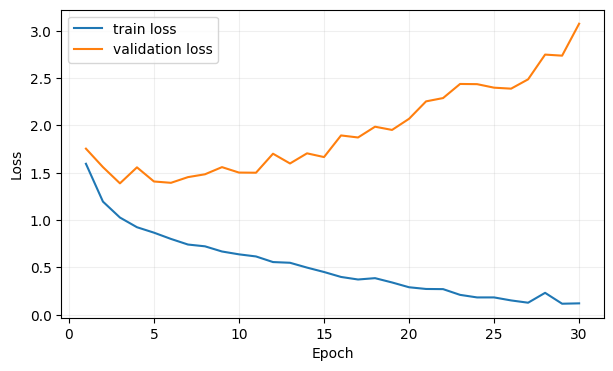

In [61]:
# Plot learning curves.
epochs = [x['epoch'] + 1 for x in history]
plt.figure(figsize=(7, 4))
plt.plot(epochs, [x['train_loss'] for x in history], label='train loss')
plt.plot(epochs, [x['val_loss'] for x in history], label='validation loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(alpha=0.2)
plt.show()


# Step 7 - Final held-out test evaluation

Only now, after the best checkpoint has been chosen from validation performance, load it and evaluate once on the test set.


In [62]:
# how well it performs on unseen data

model.load_state_dict(best_model_state)
test_metrics = evaluate(model, criterion, test_loader, device, conf)

print('Best validation epoch:', best_epoch + 1)
print('Final test metrics:')
for key, value in test_metrics.items():
    print(f'  {key}: {value:.4f}')


Best validation epoch: 10
Final test metrics:
  auc: 0.7919
  acc: 40.6977
  f1: 0.3439
  loss: 1.6356


# Step 8 -  Inspect Attention on One Slide

Attention is useful for understanding which instances contribute strongly to the learned bag representation, but attention weights should not automatically be interpreted as causal explanations.


In [63]:
one_batch = mil_collate_fn([test_data[0]])
model.eval()
with torch.no_grad():
    logits, attention = model(
        one_batch['input'].to(device, dtype=torch.float32),
        return_attention=True,
    )

print('Slide:', one_batch['slide_id'][0])
print('Predicted class:', int(logits.argmax(dim=1)[0]))
print('Attention shape:', tuple(attention.shape))
print('Attention sum for first slide:', float(attention[0].sum()))


Slide: BRACS_1003691
Predicted class: 5
Attention shape: (1, 1, 6708)
Attention sum for first slide: 1.0


## Visualize Attention on Whole-Slide Images (WSIs)

Before running the attention visualization, please complete the following steps:

1. Visit the [ECE1512-WSI-Feature dataset on Hugging Face](https://huggingface.co/datasets/LeonYe/ECE1512-WSI-Feature)

2. Download the original WSIs `test_067.tif` and `test_068.tif` and the corresponding tumor annotation file `test_068.xml`.

3. Create a folder named `slide/` under your project directory and place the downloaded files in this folder.

Run this cell after training and final test evaluation, with `DATASET = 'C16'`. It restores `best_model_state` and plots the two slides in `PROJECT_DIR/slide`:

- **test_068 (tumor):** attention overlay and green contours from `test_068.xml`, including a zoom of the annotated region.
- **test_067 (normal):** attention overlay without annotation contours, including a zoom around the highest-attention patch.

The blue rectangle marks the zoom shown on the right. Colors show **attention percentiles within each slide**, not patch tumor probabilities; areas without extracted patches stay transparent. The displayed `P(tumor)` is the model's slide-level prediction.

HDF5 patch coordinates and XML contour coordinates are assumed to be expressed in level-0 `(x, y)`  coordinates; patch coordinates are treated as top-left corners. The function parameter `patch_size_level0=512` is an editable **assumption** for the patch footprint because these HDF5 files do not store patch-size metadata. Match it to the feature extractor's patch size for an exact footprint. All visualization functions are in `wsi_visualization.py`; the cell below only calls `visualize_wsi_attention`.

[OpenSlide Python](https://openslide.org/api/python/) reads a thumbnail and a pyramid-level crop rather than loading the full-resolution WSI into memory. If dependencies are missing, run `%pip install openslide-python openslide-bin` and restart the kernel if needed. Raw per-patch attention and coordinates are retained in `attention_visualizations`.


In [64]:
if DATASET == 'C16':
    attention_visualizations = visualize_wsi_attention(model, conf, PROJECT_DIR, best_model_state)


# Step 9 - Research extension: propose two ideas, implement one of them

After completing the ABMIL baseline, propose **two distinct research ideas**. Select **one** for implementation and evaluation on **CAMELYON16 (C16), CAMELYON17 (C17), and BRACS**. You may explore explainability, more advanced model structures, improved objectives beyond cross-entropy, or another well-motivated direction.

**A negative result will not be penalized if the design choices, experiments, observations, and possible reasons for failure are well justified.** Report evidence relevant to your hypothesis: an explainability idea, for example, needs an explanation evaluation in addition to classification results.

Feel free to contact your TA to discuss your research ideas.

### Extension 1 (implemented): Critical-instance-guided gated attention

**Hypothesis:** ABMIL may improve slide-level classification when its learned gated-attention scores also account for similarity to the most discriminative patch. Inspired by Li *et al.* (DSMIL, 2021), we select a class-specific critical instance using an auxiliary instance scorer, then combine gated-attention logits with learned query similarity to that critical instance.

This is **not full DSMIL**: we retain ABMIL's dimensionality reduction, gated attention, and bag classifier, and do not implement DSMIL's dual-stream score averaging, contrastive pretraining, or multiscale fusion. The auxiliary instance scorer is trained through the similarity-guided bag prediction; no patch labels are used. For multiclass datasets, each class has its own critical patch and attention distribution. Final logits are computed using the corresponding class-specific bag representation.

The existing data loaders, cross-entropy objective, and `train_one_epoch` / `evaluate` functions are reused. The model's `forward` returns `[B, C]` logits, and optionally `[B, C, N]` attention. All three datasets must be run separately with their respective configurations.

In [65]:
class CriticalInstanceABMIL(nn.Module):
    """ABMIL with DSMIL-inspired class-specific critical-instance similarity.

    Input: [B, N, D_feat]; output logits: [B, C].
    Attention when requested: [B, C, N], one normalized distribution per class.
    """
    def __init__(self, conf):
        super().__init__()
        self.n_class = int(conf.n_class) # no. of classes being predicted
        self.dimreduction = DimReduction(conf.D_feat, conf.D_inner) # reduces the sixe of each patch embedding 
        self.attention = AttentionGated(conf.D_inner, conf.D_attn, K=1) # calculates the orginal gated attention scores

        self.instance_scorer = nn.Linear(conf.D_inner, self.n_class) # assigns a score to every patch for every class
        self.query = nn.Linear(conf.D_inner, conf.D_attn, bias=False) # transforms patch features into a different feature space for calculating similarity
        self.similarity_scale = nn.Parameter(torch.tensor(0.0)) # creates a trainable parameter that controls how much the similarity scores influence attention

        # final classifier which converts aggregated patch features into class prediction scores
        self.classifier = Classifier1FC(conf.D_inner, self.n_class, conf.droprate)

    def forward(self, x, return_attention=False, return_aux=False):
        # x: [B, N, D_feat]; variable N is supported (no padded positions assumed)
        h = self.dimreduction(x)                         # [B, N, L]
        batch_size, num_patches, hidden_dim = h.shape
        gated_logits = self.attention(h)                 # [B, 1, N]

        # a critical patch is selected independently for each target class

        #each patch receives two scores, one for each class
        patch_scores = self.instance_scorer(h)           # [B, N, C]

        #finds patch with highest score for each class
        critical_indices = patch_scores.argmax(dim=1)   # [B, C]

        # retrieves the actual feature vectors corresponding to the selected critical patches
        critical_h = h.gather(1, critical_indices.unsqueeze(-1).expand(-1, -1, hidden_dim)) # [B, C, L]

        q = F.normalize(self.query(h), dim=-1)           # [B, N, A]
        critical_q = F.normalize(self.query(critical_h), dim=-1)  # [B, C, A]

        # calculates the similarity between every patch and each class's critical patch
        similarity = torch.einsum('bna,bca->bcn', q, critical_q)  # [B, C, N]

        # learned nonnegative strength -> starts at 1 for a meaningful similarity signal
        strength = F.softplus(self.similarity_scale) / F.softplus(torch.zeros_like(self.similarity_scale))
        attention = torch.softmax(gated_logits + strength * similarity, dim=-1)

        # combines the patch feature vectors using their corresponding attention weights
        # create one aggregated feature vector for each class instead of one (like in ABMIL baseline)
        class_bags = torch.bmm(attention, h)             # [B, C, L]

        # apply the shared ABMIL classifier to each class-conditioned bag and
        # then select the matching class logit from each classifier output
        all_class_logits = self.classifier(class_bags)   # [B, C, C]
        logits = all_class_logits.diagonal(dim1=1, dim2=2)  # [B, C]
        if return_attention:
            return logits, attention
        if return_aux:
            return logits, patch_scores.max(dim=1).values
        return logits

### Sanity Checks

Before training, check that the model produces the correct output shapes, normalized attention weights, valid values, and gradients. One limitation is that `argmax` selects the highest-scoring patch but does not allow gradients to pass through the selection process. This means the instance scorer cannot learn from the final classification loss through this selection. However, the other parts of the model can still be trained normally. To address this limitation, an additional loss is introduced to train the instance scorer directly using the WSI labels.

In [66]:
extension_cpu = CriticalInstanceABMIL(conf)
with torch.no_grad():
    sample_logits, sample_attn = extension_cpu(torch.randn(2, 7, conf.D_feat), return_attention=True)
assert sample_logits.shape == (2, conf.n_class)
assert sample_attn.shape == (2, conf.n_class, 7)
assert torch.allclose(sample_attn.sum(dim=-1), torch.ones(2, conf.n_class), atol=1e-5)
assert torch.isfinite(sample_logits).all()
print('Extension sanity checks passed:', sample_logits.shape, sample_attn.shape)

Extension sanity checks passed: torch.Size([2, 7]) torch.Size([2, 7, 7])


### Train and Evaluate the Extension

The auxiliary max-instance cross-entropy term trains the critical-instance selector using **slide-level labels only**. Its coefficient is a tunable hyperparameter; keep it fixed across datasets for the primary experiment and report it. The final test set is evaluated only after selecting the best checkpoint using validation AUROC + F1, matching the baseline. Run the baseline first so its `test_metrics` are available for comparison.

In [67]:
# preserve the current dataset's baseline results before training the extension.
baseline_metrics = dict(test_metrics) if 'test_metrics' in globals() else None

# 25% of additional instance-level loss contributes to the total training loss
AUX_LOSS_WEIGHT = 0.25  # slide-level auxiliary supervision for critical patch scorer
extension_model = CriticalInstanceABMIL(conf).to(device)
extension_optimizer = torch.optim.AdamW(
    extension_model.parameters(), lr=conf.lr, weight_decay=conf.wd
)

def train_extension_epoch(model, loader, optimizer, device, aux_weight=0.25):
    model.train()
    total_loss = total_correct = total_examples = 0
    for data in loader:
        bag = data['input'].to(device, dtype=torch.float32)
        labels = data['label'].to(device, dtype=torch.long)
        optimizer.zero_grad()
        logits, instance_logits = model(bag, return_aux=True)

        # main classification loss and auxiliary loss
        loss = F.cross_entropy(logits, labels) + aux_weight * F.cross_entropy(instance_logits, labels)

        # calculate the gradients
        loss.backward()

        # use the gradients to update the weights 
        optimizer.step()
        count = labels.size(0)
        total_loss += loss.item() * count
        total_correct += (logits.argmax(1) == labels).sum().item()
        total_examples += count
    return {'loss': total_loss / total_examples, 'acc': 100.0 * total_correct / total_examples}

extension_history = []
extension_best_score = float('-inf')
extension_best_epoch = -1
extension_best_state = None
for epoch in range(int(conf.train_epoch)):
    start = time.time()
    tr = train_extension_epoch(extension_model, train_loader, extension_optimizer, device, AUX_LOSS_WEIGHT)
    va = evaluate(extension_model, criterion, val_loader, device, conf)
    score = va['auc'] + va['f1']
    if score > extension_best_score:
        extension_best_score = score
        extension_best_epoch = epoch
        extension_best_state = copy.deepcopy(extension_model.state_dict())
    extension_history.append({'epoch': epoch + 1, 'train_loss': tr['loss'], 'val_loss': va['loss'],
                              'val_acc': va['acc'], 'val_auc': va['auc'], 'val_f1': va['f1']})
    print(f"Extension epoch {epoch+1}/{int(conf.train_epoch)}: "
          f"train_loss={tr['loss']:.4f} val_loss={va['loss']:.4f} "
          f"val_auc={va['auc']:.4f} val_f1={va['f1']:.4f} "
          f"best={extension_best_epoch+1} ({time.time()-start:.1f}s)")

Extension epoch 1/30: train_loss=2.0334 val_loss=1.7417 val_auc=0.6837 val_f1=0.1013 best=1 (83.6s)
Extension epoch 2/30: train_loss=1.6346 val_loss=1.5271 val_auc=0.7529 val_f1=0.3043 best=2 (82.6s)
Extension epoch 3/30: train_loss=1.3787 val_loss=1.4682 val_auc=0.7961 val_f1=0.3199 best=3 (82.6s)
Extension epoch 4/30: train_loss=1.2333 val_loss=1.3703 val_auc=0.8234 val_f1=0.3666 best=4 (315.9s)
Extension epoch 5/30: train_loss=1.1570 val_loss=1.4005 val_auc=0.8213 val_f1=0.3989 best=5 (110.2s)
Extension epoch 6/30: train_loss=1.0679 val_loss=1.5678 val_auc=0.7974 val_f1=0.3040 best=5 (109.3s)
Extension epoch 7/30: train_loss=1.0120 val_loss=1.4269 val_auc=0.8249 val_f1=0.4156 best=7 (112.1s)
Extension epoch 8/30: train_loss=0.9441 val_loss=1.4633 val_auc=0.8239 val_f1=0.3641 best=7 (114.2s)
Extension epoch 9/30: train_loss=0.9261 val_loss=1.5135 val_auc=0.8151 val_f1=0.3481 best=7 (115.3s)
Extension epoch 10/30: train_loss=0.8780 val_loss=1.5669 val_auc=0.8242 val_f1=0.3389 best=7 (

### Final Model Evaluation

After training, the best-performing model checkpoint is loaded based on the combined validation AUROC and F1-score. The selected model is then evaluated on the held-out test set to measure its performance on unseen WSIs. The resulting test metrics, including accuracy, AUROC, F1-score, and loss, are displayed alongside the baseline ABMIL results to compare the performance of the proposed extension.

In [68]:
extension_model.load_state_dict(extension_best_state)
extension_test_metrics = evaluate(extension_model, criterion, test_loader, device, conf)
print('Dataset:', DATASET, '| selected epoch:', extension_best_epoch + 1)
print('Extension test metrics:', extension_test_metrics)
if baseline_metrics is not None:
    print('Baseline test metrics:', baseline_metrics)

Dataset: BRACS | selected epoch: 7
Extension test metrics: {'auc': 0.8169646263122559, 'acc': 44.186046719551086, 'f1': 0.3694045841693878, 'loss': 1.3690879278691745}
Baseline test metrics: {'auc': 0.791863739490509, 'acc': 40.697672963142395, 'f1': 0.34387505054473877, 'loss': 1.6356001101179742}


### Performance Comparison and Results

The training and validation loss curves are plotted to show how the proposed extension performs across epochs. The training loss includes both the classification and auxiliary losses, while the validation loss only includes the classification loss. The extension's test results are then compared with the baseline ABMIL model using accuracy, AUROC, F1-score, and loss. Finally, the results are saved in a JSON file for each dataset (CAMELYON16, CAMELYON17, and BRACS) to support further analysis and comparison.

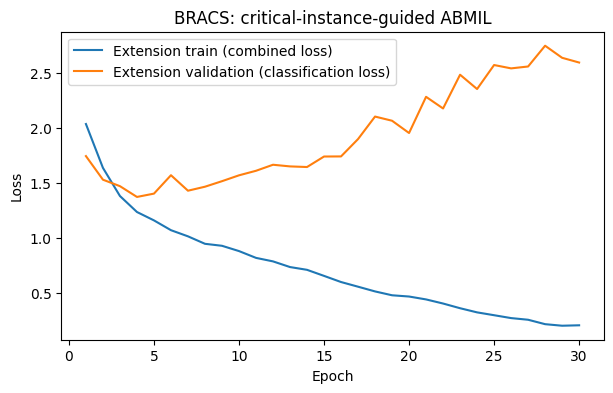

Comparison for BRACS:
  acc: baseline=40.6977 | extension=44.1860 | difference=+3.4884
  auc: baseline=0.7919 | extension=0.8170 | difference=+0.0251
   f1: baseline=0.3439 | extension=0.3694 | difference=+0.0255
 loss: baseline=1.6356 | extension=1.3691 | difference=-0.2665
Saved: critical_instance_results_BRACS.json


In [ ]:
# visual comparison for the current dataset.
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot([r['epoch'] for r in extension_history], [r['train_loss'] for r in extension_history], label='Extension train (combined loss)')
ax.plot([r['epoch'] for r in extension_history], [r['val_loss'] for r in extension_history], label='Extension validation (classification loss)')
ax.set(xlabel='Epoch', ylabel='Loss', title=f'{DATASET}: critical-instance-guided ABMIL')
ax.legend()
plt.show()

if baseline_metrics is not None:
    print(f'Comparison for {DATASET}:')
    for metric in ('acc', 'auc', 'f1', 'loss'):
        if metric in baseline_metrics and metric in extension_test_metrics:
            b, e = baseline_metrics[metric], extension_test_metrics[metric]
            print(f'{metric:>5}: baseline={b:.4f} | extension={e:.4f} | difference={e-b:+.4f}')

# save a small per-dataset summary (repeat with DATASET=C16, C17, BRACS)
# create folder for results
results_dir = Path(PROJECT_DIR) / 'critical_instance_results'
results_dir.mkdir(parents=True, exist_ok=True)

# save per-dataset summary
summary_path = results_dir / f'critical_instance_results_{DATASET}.json'

with open(summary_path, 'w') as f:
    json.dump({
        'dataset': DATASET,
        'aux_loss_weight': AUX_LOSS_WEIGHT,
        'selected_epoch': extension_best_epoch + 1,
        'baseline': baseline_metrics,
        'extension': extension_test_metrics
    }, f, indent=2, default=float)

print('Saved:', summary_path)


### Attention Inspection and Experimental Reporting

For multiclass classification, `attention[0, predicted_class]` retrieves the attention weights for the predicted class. These weights add up to 1 across all patches. Since this extension produces separate attention weights for each class (`[B, C, N]`), existing visualization functions may need to be adjusted. However, high attention weights do not necessarily mean that a patch contains a tumor, as this would require additional verification using annotated data.`

In [70]:
extension_model.eval()
with torch.no_grad():
    sample = mil_collate_fn([test_data[0]])
    logits, attention = extension_model(sample['input'].to(device, dtype=torch.float32), return_attention=True)
    predicted_class = int(logits.argmax(dim=1)[0])
    predicted_class_attention = attention[0, predicted_class]
print('Slide:', sample['slide_id'][0], 'predicted class:', predicted_class)
print('Class-specific attention shape:', tuple(predicted_class_attention.shape))
print('Attention sum:', float(predicted_class_attention.sum()))

Slide: BRACS_1003691 predicted class: 5
Class-specific attention shape: (6708,)
Attention sum: 0.9999999403953552
